# Transfer learning · EfficientNetB0 · experiment06

**Autores:** [completar] · **Experimento:** efficientnet_b0_tl_experiment06

**Hipótesis:** un LR inicial de **3e-5**, frente a **1e-5** en experiment05, puede mejorar la
adaptación a xView. **Es el único cambio de entrenamiento**; no se presupone una mejora.

Se mantienen **192×192**, batch **32**, MixUp **alpha=0.2**, fine-tuning de todo el backbone salvo
BatchNorm, AdamW nuevo, weight decay **1e-4**, sin label smoothing ni Dropout adicional,
semilla 42, reparto, giros/flips y los mismos callbacks. El mínimo de LR continúa en **1e-6**.
Hasta 180 épocas adicionales, máximo 200 contando la cabeza en esta rama independiente.

Se vuelve a partir del mejor **experiment01**, entrenado a 128×128. Se reconstruyen la entrada y
el backbone a 192×192, copiando exactamente todos sus pesos, incluida la cabeza. No se continúa
desde experiment05. Se reutiliza la caché mmap de 192×192 de TL.

**Requisito:** conservar `model.keras` y `artifacts/` de experiment01. Se evalúa el extractor adaptado
a 192 antes de entrenar para fijar el umbral de selección. Si no se mejora, se conserva ese modelo
adaptado, con su entrada correcta y métricas reevaluadas.

Reinicia el kernel y ejecuta todas las celdas en orden. Se guardan los resultados en esta carpeta:
mejor `model.keras`, **un `prediction.json` nuevo**, artefactos y PDF. El JSON se calcula con el
checkpoint seleccionado de esta ejecución; no se copia de experimentos anteriores.
La comparación incluye scratch y experiment01/02/03/04/05/06 de TL.
[Protocolo y registro](../../README.md).


## 1. Configuración y entorno

Dependencias: TensorFlow/Keras con AdamW y ModelCheckpoint.initial_value_threshold, NumPy,
scikit-learn, Rasterio, Matplotlib y Jupyter. Compatible con el entorno TensorFlow 2.15.1 del proyecto.
No se instalan paquetes automáticamente. Solo experiment01 descarga pesos ImageNet al construir el modelo.

Mismo reparto 90/10, random_state=1, sin estratificación, orden y clases del challenge anterior.
Las rutas se resuelven respecto a PROJECT; se permiten overrides y rutas absolutas, sin rutas personales.
No hace falta tener el dataset disponible para ejecutar solo configuración y comparaciones desde artefactos.


In [1]:
from pathlib import Path
import os
import shutil
import csv
import hashlib
import json
import platform
import tempfile
import time
import warnings

import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_recall_fscore_support,
                             precision_recall_curve, average_precision_score)

def read_json(path):
    with Path(path).open(encoding='utf-8') as stream:
        return json.load(stream)

def write_json(path, data):
    with Path(path).open('w', encoding='utf-8') as stream:
        json.dump(data, stream, indent=2, ensure_ascii=False, allow_nan=False)

def digest_json(data):
    return hashlib.sha256(json.dumps(data, sort_keys=True).encode()).hexdigest()


def artifact_path(run_dir, filename):
    """Leer artifacts/; aceptar también los resultados antiguos en la raíz."""
    path = Path(run_dir) / 'artifacts' / filename
    return path if path.exists() else Path(run_dir) / filename


def save_figure(fig, directory, name):
    directory.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(directory / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)

# EDITAR: identidad, hipótesis y factores que se modifican.
CFG = {'experiment_id': 'efficientnet_b0_tl_experiment06',
 'hypothesis': 'EfficientNetB0: probar LR inicial 3e-5 frente a 1e-5, manteniendo los ajustes de experiment05 a 192x192.',
 'architecture': 'efficientnet_b0',
 'stage': 'fine_tuning',
 'seed': 42,
 'deterministic': True,
 'image_size': [192, 192],
 'source_image_size': [128, 128],
 'batch_size': 32,
 'max_epochs': 180,
 'optimizer': 'adamw',
 'learning_rate': 3e-05,
 'weight_decay': 0.0001,
 'clipnorm': None,
 'dropout': 0.0,
 'l2': 0.0,
 'label_smoothing': 0.0,
 'augmentation': True,
 'mixup_alpha': 0.2,
 'lr_factor': 0.5,
 'lr_patience': 10,
 'stop_patience': 20,
 'min_lr': 1e-06,
 'monitor': 'val_accuracy',
 'monitor_mode': 'max',
 'unfreeze_scope': 'all_except_batch_norm',
 'unfreeze_prefixes': []}
# EDITAR al copiar: ruta del notebook relativa a PROJECT (también admite una ruta absoluta).
# Los archivos model.keras y prediction.json se escriben en la carpeta de esta ruta.
NOTEBOOK_PATH = Path('tl_challenge/efficientnet_b0/experiment06/efficientnet_b0_tl_experiment06.ipynb')
SOURCE_RUN_PATH = Path('tl_challenge/efficientnet_b0/experiment01')
CACHE_MODE = 'mmap'                # Siempre lotes desde la caché en disco
DATA_DIR_OVERRIDE = None            # p. ej. Path('/ruta/xview_recognition')
PROJECT_DIR_OVERRIDE = None         # si se lanza Jupyter fuera del repositorio

CATEGORY_NAMES = ['Cargo plane', 'Small car', 'Bus', 'Truck', 'Motorboat',
                  'Fishing vessel', 'Dump truck', 'Excavator', 'Building',
                  'Helipad', 'Storage tank', 'Shipping container', 'Pylon']
CLASS_TO_INDEX = {name: i for i, name in enumerate(CATEGORY_NAMES)}
NUM_CLASSES = len(CATEGORY_NAMES)
SPLIT_SPEC = {'validation_fraction': 0.1, 'random_state': 1, 'shuffle': True, 'stratify': None}

def find_project_dir():
    if PROJECT_DIR_OVERRIDE is not None:
        project = Path(PROJECT_DIR_OVERRIDE).expanduser().resolve()
        if not (project / 'tl_challenge').is_dir():
            raise FileNotFoundError(f'PROJECT_DIR_OVERRIDE debe apuntar a PROJECT: {project}')
        return project
    # Funciona desde la raíz del clon, PROJECT o cualquier carpeta de experimentos.
    # Una ruta absoluta del notebook permite localizar PROJECT incluso desde fuera del clon.
    notebook = Path(NOTEBOOK_PATH).expanduser()
    starts = [Path.cwd()]
    if notebook.is_absolute():
        starts.append(notebook.parent)
    for start in starts:
        for parent in (start, *start.parents):
            for candidate in (parent, parent / 'PROJECT'):
                if (candidate / 'tl_challenge').is_dir():
                    return candidate.resolve()
    raise FileNotFoundError('Define PROJECT_DIR_OVERRIDE con la ruta local a PROJECT.')


def project_path(path):
    """Las rutas relativas de configuración siempre se interpretan desde PROJECT."""
    path = Path(path).expanduser()
    return (path if path.is_absolute() else PROJECT_DIR / path).resolve()


PROJECT_DIR = find_project_dir()
DATA_DIR = project_path(DATA_DIR_OVERRIDE if DATA_DIR_OVERRIDE is not None else 'xview_recognition')
CHALLENGE_DIR = PROJECT_DIR / 'tl_challenge'
CACHE_DIR = CHALLENGE_DIR / '.cache'
NOTEBOOK_PATH = project_path(NOTEBOOK_PATH)
if not NOTEBOOK_PATH.is_file() or NOTEBOOK_PATH.suffix != '.ipynb':
    raise FileNotFoundError(f'Ajusta NOTEBOOK_PATH al notebook que estás ejecutando: {NOTEBOOK_PATH}')
RUN_DIR = NOTEBOOK_PATH.parent
ARTIFACTS_DIR = RUN_DIR / 'artifacts'
SOURCE_RUN_DIR = project_path(SOURCE_RUN_PATH) if SOURCE_RUN_PATH is not None else None

# Ejecutar desde un kernel nuevo para fijar la caché antes de importar TensorFlow/Keras.
os.environ['KERAS_HOME'] = str(CHALLENGE_DIR / '.weights')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers



@keras.utils.register_keras_serializable(package='TLChallenge')
class FrozenBatchNormalization(layers.BatchNormalization):
    """BN de inferencia con operaciones elementales y gradiente respecto a la entrada."""
    def __init__(self, **kwargs):
        kwargs['trainable'] = False
        super().__init__(**kwargs)

    def call(self, inputs, training=None):
        # Los backbones seleccionados son channels_last. No se actualizan estadísticas.
        return tf.nn.batch_normalization(
            inputs, self.moving_mean, self.moving_variance,
            self.beta if self.center else None,
            self.gamma if self.scale else None, self.epsilon)


def clone_with_frozen_batch_norm(model, image_size=None):
    """Adaptar entradas espaciales y conservar exactamente los pesos; BN explícita congelada."""
    def clone_graph(graph):
        inputs = None
        if image_size is not None:
            if len(graph.inputs) != 1 or len(graph.input_shape) != 4:
                raise ValueError('Se esperaba un modelo RGB con una sola entrada espacial.')
            inputs = keras.Input(shape=(*image_size, graph.input_shape[-1]),
                                 dtype=graph.inputs[0].dtype,
                                 name=graph.inputs[0].name.split(':')[0])
        return keras.models.clone_model(graph, input_tensors=inputs, clone_function=clone_layer)

    def clone_layer(layer):
        if isinstance(layer, keras.Model):
            return clone_graph(layer)
        if isinstance(layer, layers.BatchNormalization):
            axes = layer.axis if isinstance(layer.axis, (tuple, list)) else [layer.axis]
            if list(axes) not in ([-1], [3]):
                raise ValueError('FrozenBatchNormalization requiere canales al final.')
            return FrozenBatchNormalization(**layer.get_config())
        return layer.__class__.from_config(layer.get_config())

    cloned = clone_graph(model)
    cloned.set_weights(model.get_weights())
    return cloned


assert CFG['stage'] in ('feature_extraction', 'fine_tuning')
assert CFG['architecture'] in ('efficientnet_b0', 'mobilenet_v2')
assert CACHE_MODE == 'mmap'
if CFG['monitor'] not in ('val_accuracy', 'val_loss', 'val_ce'):
    raise ValueError('Monitor permitido: val_accuracy, val_loss o val_ce.')
assert CFG['monitor_mode'] == ('max' if CFG['monitor'] == 'val_accuracy' else 'min')
assert CFG['stop_patience'] > CFG['lr_patience']
assert len(CFG['image_size']) == 2 and min(CFG['image_size']) >= 8
assert CFG['batch_size'] > 0 and CFG['max_epochs'] > 0
assert np.isfinite(CFG['mixup_alpha']) and CFG['mixup_alpha'] >= 0
assert 0 <= CFG['dropout'] < 1 and CFG['l2'] >= 0
assert 0 <= CFG['label_smoothing'] < 1 and CFG['weight_decay'] >= 0
assert 0 < CFG['lr_factor'] < 1 and 0 < CFG['min_lr'] <= CFG['learning_rate']
assert CFG['optimizer'] in ('sgd', 'adam', 'adamw')
if CFG['optimizer'] != 'adamw' and CFG['weight_decay'] != 0:
    raise ValueError('weight_decay requiere AdamW; usa l2 para penalización en la CNN propia.')
if CFG['augmentation'] and CFG['image_size'][0] != CFG['image_size'][1]:
    raise ValueError('Las rotaciones de 90° requieren imágenes cuadradas.')
assert Path(CFG['experiment_id']).name == CFG['experiment_id'] and CFG['experiment_id'] not in ('', '.', '..')
keras.utils.set_random_seed(CFG['seed'])
if CFG['deterministic']:
    tf.config.experimental.enable_op_determinism()
GPUS = tf.config.list_physical_devices('GPU')
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # El dispositivo ya estaba inicializado en este kernel.
print('TensorFlow:', tf.__version__, '| GPU:', GPUS)
print('Datos:', DATA_DIR, '\nResultados:', RUN_DIR)


2026-11-08 16:21:04.632724: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-08 16:21:04.951810: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-08 16:21:04.951900: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-08 16:21:05.004827: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-08 16:21:05.106975: I tensorflow/core/platform/cpu_feature_guar

TensorFlow: 2.15.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Datos: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/xview_recognition 
Resultados: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/tl_challenge/efficientnet_b0/experiment06


2026-11-08 16:21:07.256849: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 16:21:07.537459: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 16:21:07.537513: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


## 2. Anotaciones y reparto verificable

Unimos anotaciones por `image_id`, evitando depender de que dos diccionarios tengan el mismo orden.
El orden de las imágenes se conserva para reproducir exactamente el reparto anterior. Guardamos nombres,
etiquetas y un hash del reparto para detectar comparaciones incompatibles. Mostramos el soporte de las clases:
Helipad tiene muy pocas muestras y su recall puede variar mucho.

In [2]:
ANNOTATION_PATH = DATA_DIR / 'xview_ann_train.json'
raw = read_json(ANNOTATION_PATH)
annotations_by_id = {}
for ann in raw['annotations'].values():
    key = ann['image_id']
    if key in annotations_by_id:
        raise ValueError(f'Se esperaba un solo objeto por recorte: {key}')
    annotations_by_id[key] = ann
records = []
for image in raw['images'].values():
    ann = annotations_by_id[image['image_id']]
    label = CLASS_TO_INDEX[ann['category_id']]
    records.append({'filename': image['filename'], 'label': label, 'image_id': image['image_id']})
if len({r['filename'] for r in records}) != len(records):
    raise ValueError('Hay imágenes repetidas.')
indices = np.arange(len(records))
train_idx, valid_idx = train_test_split(
    indices, test_size=SPLIT_SPEC['validation_fraction'], random_state=SPLIT_SPEC['random_state'],
    shuffle=True, stratify=None,
)
labels = np.array([r['label'] for r in records], dtype=np.int32)
SPLIT_MANIFEST = {
    'spec': SPLIT_SPEC,
    'train': [records[i] for i in train_idx],
    'valid': [records[i] for i in valid_idx],
}
SPLIT_HASH = digest_json(SPLIT_MANIFEST)
DATA_HASH = hashlib.sha256(ANNOTATION_PATH.read_bytes()).hexdigest()
assert not set(train_idx) & set(valid_idx)
print(f'Train: {len(train_idx)} | Validación: {len(valid_idx)} | hash: {SPLIT_HASH[:12]}')
print(f"{'Clase':22} {'train':>7} {'valid':>7}")
for i, name in enumerate(CATEGORY_NAMES):
    print(f'{name:22} {np.sum(labels[train_idx] == i):7} {np.sum(labels[valid_idx] == i):7}')
if set(labels[valid_idx]) != set(range(NUM_CLASSES)):
    raise ValueError('Hay clases ausentes en validación: revisar el protocolo antes de continuar.')

Train: 16871 | Validación: 1875 | hash: f7d0f1df9d98
Clase                    train   valid
Cargo plane                576      59
Small car                 2995     329
Bus                       1594     174
Truck                     1969     241
Motorboat                  960     109
Fishing vessel             633      73
Dump truck                1118     118
Excavator                  708      81
Building                  3231     363
Helipad                    102       9
Storage tank              1317     152
Shipping container        1388     135
Pylon                      280      32


## 3. Caché en disco y lotes

Los experimentos de esta versión comparten su propia caché `PROJECT/tl_challenge/.cache/`: RGB float32 [0,1],
reducción con `Resampling.average`, escritura imagen a imagen y publicación atómica.
La clave incluye raíz, anotaciones, orden de archivos, resolución y preprocesamiento.
**Si cambias el contenido de los TIFF, elimina su caché**. A 192×192 ocupa unos 7,72 GiB; su clave es distinta de la caché de 128×128, que se conserva.

Siempre se abre con `mmap`: solo se copian lotes y se anticipa un lote. Las etiquetas son one-hot
para usar Categorical Cross Entropy y permitir label smoothing.
Si `augmentation=True`, cada imagen de train recibe una rotación uniforme entre 0°, 90°, 180°, 270°
y flips horizontal/vertical independientes con p=0.5. Se aplica en el dataset de entrenamiento;
validación, evaluación de train y test conservan sus píxeles sin aumentación.

La caché contiene RGB [0,1] sin preprocesamiento específico de red. Las transformaciones
de ImageNet se integran en el modelo, de forma idéntica en train, validación y test.

**MixUp solo en train:** después de los giros y flips, cada imagen se combina con una pareja
aleatoria del mismo lote mediante `lambda ~ Beta(0.2, 0.2)`, independiente por ejemplo.
Se usa el mismo lambda para los píxeles y las etiquetas. El muestreo NumPy tiene un RNG
independiente del barajado y no necesita kernels aleatorios Gamma en GPU.
Validación, train de evaluación y test no reciben MixUp.


In [3]:
def read_image(path, image_size):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
        with rasterio.open(path) as src:
            if src.count != 3 or any(dtype != 'uint8' for dtype in src.dtypes):
                raise ValueError(f'Se esperaba RGB uint8: {path}')
            bands = src.read(out_shape=(3, *image_size), out_dtype='float32', resampling=Resampling.average)
    return np.moveaxis(bands, 0, -1) / np.float32(255.0)

def prepare_cache(records, image_size):
    # Incluye raíz del dataset: no mezclar copias distintas con las mismas anotaciones.
    spec = {'data_dir': str(DATA_DIR.resolve()), 'data_hash': DATA_HASH,
            'files': [r['filename'] for r in records], 'image_size': list(image_size),
            'reader': 'rasterio-average-float32-rgb-div255-v1'}
    key = digest_json(spec)
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    path = CACHE_DIR / f'{key}.npy'
    shape = (len(records), *image_size, 3)
    print(f'Caché de imágenes: {np.prod(shape) * 4 / 1024**3:.2f} GiB en disco; modo mmap')
    if not path.exists():
        # Escribir imagen a imagen: tampoco durante la creación se reserva el array completo en RAM.
        with tempfile.NamedTemporaryFile(dir=CACHE_DIR, suffix='.tmp.npy', delete=False) as stream:
            temp = Path(stream.name)
        try:
            array = np.lib.format.open_memmap(temp, mode='w+', dtype=np.float32, shape=shape)
            try:
                for i, record in enumerate(records):
                    array[i] = read_image(DATA_DIR / record['filename'], image_size)
                    if (i + 1) % 2000 == 0:
                        print(f'  {i + 1}/{len(records)}')
                array.flush()
            finally:
                del array
            temp.replace(path)  # Solo publicar una caché completamente escrita.
        finally:
            temp.unlink(missing_ok=True)
    array = np.load(path, mmap_mode='r', allow_pickle=False)
    if array.shape != shape or array.dtype != np.float32:
        raise ValueError(f'Caché incompatible: elimina {path} y vuelve a preparar los datos.')
    return array

load_start = time.perf_counter()
x_all = prepare_cache(records, CFG['image_size'])
load_seconds = time.perf_counter() - load_start
print(f'Datos preparados en {load_seconds:.1f} s; forma: {x_all.shape}')

def make_dataset(array, all_labels, selected_idx, batch_size, shuffle=False, seed=42, augment=False, mixup_alpha=0.0):
    # Un generador por dataset, con RNG independiente de la inicialización del modelo.
    if mixup_alpha < 0:
        raise ValueError("mixup_alpha debe ser no negativo.")
    rng = np.random.default_rng(seed)
    mix_rng = np.random.default_rng(seed + 1000)  # Independiente del orden de los ejemplos.
    selected_idx = np.asarray(selected_idx)
    def batches():
        order = rng.permutation(selected_idx) if shuffle else selected_idx
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            images = np.asarray(array[batch], dtype=np.float32)
            targets = np.eye(NUM_CLASSES, dtype=np.float32)[all_labels[batch]]
            if mixup_alpha > 0:
                weights = mix_rng.beta(mixup_alpha, mixup_alpha, size=len(batch)).astype(np.float32)
                partners = mix_rng.permutation(len(batch)).astype(np.int32)
                yield images, targets, weights, partners
            else:
                yield images, targets
    signature = (tf.TensorSpec((None, *array.shape[1:]), tf.float32),
                 tf.TensorSpec((None, NUM_CLASSES), tf.float32))
    if mixup_alpha > 0:
        signature += (tf.TensorSpec((None,), tf.float32), tf.TensorSpec((None,), tf.int32))
    ds = tf.data.Dataset.from_generator(batches, output_signature=signature)
    ds = ds.apply(tf.data.experimental.assert_cardinality(int(np.ceil(len(selected_idx) / batch_size))))
    options = tf.data.Options()
    options.experimental_deterministic = True
    ds = ds.with_options(options)
    if augment:
        def augment_batch(images, targets, *mix_metadata):
            def augment_image(image):
                k = tf.random.uniform((), maxval=4, dtype=tf.int32)
                image = tf.image.rot90(image, k)
                image = tf.image.random_flip_left_right(image)
                return tf.image.random_flip_up_down(image)
            images = tf.map_fn(augment_image, images,
                               fn_output_signature=tf.TensorSpec(array.shape[1:], tf.float32))
            return (images, targets, *mix_metadata)
        ds = ds.map(augment_batch, num_parallel_calls=1, deterministic=True)
    if mixup_alpha > 0:
        # Mezclar después de transformar cada imagen; usar idéntico lambda y pareja para imagen/etiqueta.
        def mixup_batch(images, targets, weights, partners):
            image_weights = tf.reshape(weights, (-1, 1, 1, 1))
            label_weights = tf.reshape(weights, (-1, 1))
            paired_images = tf.gather(images, partners)
            paired_targets = tf.gather(targets, partners)
            return (image_weights * images + (1.0 - image_weights) * paired_images,
                    label_weights * targets + (1.0 - label_weights) * paired_targets)
        ds = ds.map(mixup_batch, num_parallel_calls=1, deterministic=True)
    return ds.prefetch(1)

train_ds = make_dataset(x_all, labels, train_idx, CFG['batch_size'], True, CFG['seed'], augment=CFG['augmentation'],
                        mixup_alpha=CFG['mixup_alpha'])
valid_ds = make_dataset(x_all, labels, valid_idx, CFG['batch_size'])
train_eval_ds = make_dataset(x_all, labels, train_idx, CFG['batch_size'])


Caché de imágenes: 7.72 GiB en disco; modo mmap


2026-11-08 16:21:07.675645: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA

Datos preparados en 0.0 s; forma: (18746, 192, 192, 3)


 node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 16:21:07.675766: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 16:21:07.675810: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 16:21:07.841344: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 16:21:07.841444: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may h

## 4. Modelo y capas entrenables

Backbone oficial EfficientNetB0 de Keras, `include_top=False`, pesos ImageNet,
GAP y Dense13 softmax, la misma cabeza que la referencia desde cero.

Se carga el mejor experiment01 y se habilitan todas las capas del backbone salvo BatchNorm (`unfreeze_scope=all_except_batch_norm`). La lista de prefijos no se utiliza en esta prueba. BatchNorm permanece congelada, incluidos sus parámetros afines. Se recompila con AdamW nuevo y LR 3e-5.

El backbone se llama con `training=False` en ambas etapas: no actualiza estadísticas BN
ni activa sus capas estocásticas internas. Esto permite gradientes en las convoluciones de todos los bloques
sin alterar ese modo de ejecución; no hay Dropout adicional en la cabeza.

La entrada pública del modelo sigue siendo RGB [0,1]. EfficientNet recibe ×255 antes de
su preprocesamiento interno; MobileNetV2 recibe 2×x−1. No se aplica dos veces la normalización.
El preprocesamiento difiere del histórico desde cero cuando lo exige ImageNet, y queda registrado.

**Compatibilidad con TensorFlow 2.15 y GPU determinista:** al cargar el extractor se clona
el grafo y se conservan todos sus pesos, sustituyendo BN por `FrozenBatchNormalization`.
La capa aplica la misma normalización de inferencia mediante operaciones elementales;
no actualiza medias, varianzas, gamma ni beta. Así se evita el gradiente no implementado
`FusedBatchNormGradV3` sin desactivar el determinismo ni descongelar BN.
La clase queda registrada en la primera celda para guardar y recargar `model.keras`.

La entrada del checkpoint original y la del backbone anidado se reconstruyen a 192×192.
Las convoluciones, normalizaciones, GAP y Dense conservan sus pesos exactamente; no se añade un
reescalado de 192 a 128 dentro del modelo. El extractor inicial se reevalúa a 192 antes de entrenar.


In [4]:
APPLICATIONS = {
    'efficientnet_b0': keras.applications.EfficientNetB0,
    'mobilenet_v2': keras.applications.MobileNetV2,
}


def hash_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def configure_backbone(backbone, cfg):
    if cfg['stage'] == 'feature_extraction':
        backbone.trainable = False
    else:
        backbone.trainable = True
        for layer in backbone.layers:
            if cfg['unfreeze_scope'] != 'all_except_batch_norm':
                raise ValueError('Este experimento requiere entrenar todo el backbone salvo BatchNorm.')
            layer.trainable = not isinstance(layer, layers.BatchNormalization)
        if not any(layer.trainable and layer.trainable_weights for layer in backbone.layers):
            raise ValueError('No se han seleccionado pesos del backbone para fine-tuning.')
    if any(layer.trainable for layer in backbone.layers if isinstance(layer, layers.BatchNormalization)):
        raise ValueError('BatchNormalization debe permanecer congelada.')


def validate_source(cfg, source_dir):
    required = ('config.json', 'metrics.json', 'history.json', 'timing.json')
    for filename in required:
        if not artifact_path(source_dir, filename).is_file():
            raise FileNotFoundError(f'Ejecuta primero experiment01 completo: falta {source_dir / "artifacts" / filename}')
    if not (source_dir / 'model.keras').is_file():
        raise FileNotFoundError(f'Falta {source_dir / "model.keras"}: los modelos no se incluyen en Git.')
    source = read_json(artifact_path(source_dir, 'config.json'))
    expected = {'architecture': cfg['architecture'], 'stage': 'feature_extraction',
                'weights': 'imagenet', 'class_names': CATEGORY_NAMES,
                'data_hash': DATA_HASH, 'split_hash': SPLIT_HASH,
                'image_size': cfg['source_image_size'], 'seed': cfg['seed']}
    for key, value in expected.items():
        if source.get(key) != value:
            raise ValueError(f'Checkpoint de origen incompatible ({key}): {source_dir}')
    if source['max_epochs'] + cfg['max_epochs'] > 200:
        raise ValueError('El presupuesto de las dos etapas no debe superar 200 épocas.')
    return source


def build_transfer_model(cfg):
    if cfg['stage'] == 'fine_tuning':
        source = validate_source(cfg, SOURCE_RUN_DIR)
        source_hash = hash_file(SOURCE_RUN_DIR / 'model.keras')
        source_model = keras.models.load_model(SOURCE_RUN_DIR / 'model.keras', compile=False)
        model = clone_with_frozen_batch_norm(source_model, cfg['image_size'])
        del source_model
        backbone = model.get_layer(cfg['architecture'] + '_backbone')
        if tuple(model.input_shape[1:]) != (*cfg['image_size'], 3) or model.output_shape[-1] != NUM_CLASSES:
            raise ValueError('Dimensiones del checkpoint de origen incompatibles.')
        configure_backbone(backbone, cfg)
        return model, backbone, source, source_hash
    application = APPLICATIONS[cfg['architecture']](weights='imagenet', include_top=False,
                                                  input_shape=(*cfg['image_size'], 3))
    backbone = keras.Model(application.input, application.output,
                           name=cfg['architecture'] + '_backbone')
    configure_backbone(backbone, cfg)
    inputs = keras.Input(shape=(*cfg['image_size'], 3), name='rgb_0_1')
    if cfg['architecture'] == 'efficientnet_b0':
        x = layers.Rescaling(255.0, name='imagenet_input_0_255')(inputs)
    else:
        x = layers.Rescaling(2.0, offset=-1.0, name='imagenet_input_neg1_1')(inputs)
    # Gradientes permitidos en fine-tuning; BN y capas estocásticas del backbone en inferencia.
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name='global_pool')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='classification')(x)
    model = keras.Model(inputs, outputs, name=cfg['architecture'] + '_transfer')
    return model, backbone, None, None


def compile_model(model, cfg):
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=cfg['learning_rate'],
                                        weight_decay=cfg['weight_decay']),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.0),
        metrics=[keras.metrics.CategoricalAccuracy(name='accuracy'),
                 keras.metrics.CategoricalCrossentropy(name='ce')],
    )
    return model


keras.backend.clear_session()
keras.utils.set_random_seed(CFG['seed'])
model, backbone, SOURCE_CONFIG, SOURCE_MODEL_SHA256 = build_transfer_model(CFG)
model = compile_model(model, CFG)
model.summary()
INITIAL_HASH = hashlib.sha256(b''.join(w.tobytes() for w in model.get_weights())).hexdigest()
TRAINABLE_PARAMS = int(sum(np.prod(w.shape) for w in model.trainable_weights))
BACKBONE_TRAINABLE_LAYERS = [layer.name for layer in backbone.layers if layer.trainable and layer.weights]
print('Parámetros entrenables:', TRAINABLE_PARAMS, '/', model.count_params())
print('Capas con pesos entrenables en backbone:', BACKBONE_TRAINABLE_LAYERS)


Model: "efficientnet_b0_transfer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rgb_0_1 (InputLayer)        [(None, 192, 192, 3)]     0         
                                                                 
 imagenet_input_0_255 (Resc  (None, 192, 192, 3)       0         
 aling)                                                          
                                                                 
 efficientnet_b0_backbone (  (None, 6, 6, 1280)        4049571   
 Functional)                                                     
                                                                 
 global_pool (GlobalAverage  (None, 1280)              0         
 Pooling2D)                                                      
                                                                 
 classification (Dense)      (None, 13)                16653     
                                          

## 5. Entrenamiento y artefactos

ModelCheckpoint selecciona el primer máximo de val_accuracy. EarlyStopping restaura pesos y
la evaluación recarga el archivo elegido, no el objeto en RAM. CSV se actualiza cada época.

En fine-tuning se conserva inicialmente una copia del mejor extractor y solo se sustituye si una
época supera su accuracy de validación. Si no mejora, prediction.json y métricas usan el extractor;
`checkpoint_stage` y `selected_from_source` lo indican. La curva sigue mostrando lo que intentó la etapa.

Se registran capas/contador de parámetros entrenables, hash del modelo de origen, etapa, época local
y global del checkpoint, épocas totales y tiempo acumulado. La primera etapa puede sobrescribir
sus propios resultados al repetirse; las carpetas anteriores nunca se modifican desde fine-tuning.

En este experimento el umbral es la accuracy **reevaluada a 192×192** del extractor original adaptado.
El fallback guarda ese mismo modelo de entrada 192 (`checkpoint_stage=feature_extraction_resized`),
no reutiliza la accuracy histórica de 128 para decidir ni copia el archivo con otra forma de entrada.


In [5]:
class EpochTelemetry(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
        self.lr = float(keras.backend.get_value(self.model.optimizer.learning_rate))
    def on_epoch_end(self, epoch, logs=None):
        logs['epoch_seconds'] = time.perf_counter() - self.start
        logs['lr_used'] = self.lr


def make_callbacks(run_dir, cfg, baseline_accuracy=None):
    return [
        EpochTelemetry(),
        keras.callbacks.ModelCheckpoint(
            str(run_dir / 'model.keras'), monitor='val_accuracy', mode='max',
            save_best_only=True, initial_value_threshold=baseline_accuracy, verbose=1),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_accuracy', mode='max', min_delta=0, factor=cfg['lr_factor'],
            patience=cfg['lr_patience'], min_lr=cfg['min_lr'], verbose=1),
        keras.callbacks.EarlyStopping(
            monitor='val_accuracy', mode='max', min_delta=0,
            patience=cfg['stop_patience'], restore_best_weights=True, verbose=1),
        keras.callbacks.TerminateOnNaN(),
        keras.callbacks.CSVLogger(str(run_dir / 'artifacts' / 'history.csv')),
    ]


def start_run(model, cfg, run_dir):
    run_dir.mkdir(parents=True, exist_ok=True)
    artifacts_dir = run_dir / 'artifacts'
    artifacts_dir.mkdir(parents=True, exist_ok=True)
    source_metrics = None
    baseline_accuracy = None
    if cfg['stage'] == 'fine_tuning':
        validate_source(cfg, SOURCE_RUN_DIR)
        if hash_file(SOURCE_RUN_DIR / 'model.keras') != SOURCE_MODEL_SHA256:
            raise ValueError('El checkpoint de origen cambió: vuelve a ejecutar desde la construcción del modelo.')
        source_metrics = read_json(artifact_path(SOURCE_RUN_DIR, 'metrics.json'))
        # El cambio de resolución modifica las predicciones incluso antes de entrenar.
        baseline_metrics = model.evaluate(valid_ds, return_dict=True, verbose=0)
        baseline_accuracy = float(baseline_metrics['accuracy'])
        print('Accuracy inicial del extractor adaptado a 192:', baseline_accuracy)
        if not np.isfinite(baseline_accuracy):
            raise ValueError('Accuracy de origen no finita.')
    for name in ('model.keras', 'prediction.json'):
        (run_dir / name).unlink(missing_ok=True)
    for name in ('metrics.json', 'history.json', 'timing.json', 'validation_predictions.npz', 'class_metrics.csv'):
        (artifacts_dir / name).unlink(missing_ok=True)
    if source_metrics is not None:
        # Guardar la entrada adaptada a 192, nunca copiar el modelo de entrada fija 128.
        model.save(run_dir / 'model.keras')
    config = {
        **cfg, 'weights': 'imagenet', 'initialization': 'imagenet' if source_metrics is None else 'feature_extraction_checkpoint',
        'all_layers_trainable': False, 'head': 'GAP-Dense13',
        'class_names': CATEGORY_NAMES, 'split_hash': SPLIT_HASH, 'data_hash': DATA_HASH,
        'split_spec': SPLIT_SPEC, 'preprocessing': 'rasterio-average-float32-rgb-div255-v1',
        'model_preprocessing': 'rgb_0_1_to_0_255_then_keras_efficientnet' if cfg['architecture'] == 'efficientnet_b0'
                               else 'rgb_0_1_to_neg1_1',
        'batch_norm_frozen': True, 'backbone_call_training': False,
        'batch_norm_implementation': 'explicit_frozen_inference',
        'trainable_params_stage': TRAINABLE_PARAMS,
        'trainable_backbone_layers': BACKBONE_TRAINABLE_LAYERS,
        'data_load_seconds': load_seconds, 'cache_mode': CACHE_MODE,
        'initial_weights_sha256': INITIAL_HASH,
        'source_run': SOURCE_RUN_DIR.relative_to(PROJECT_DIR).as_posix() if source_metrics is not None else None,
        'source_model_sha256': SOURCE_MODEL_SHA256,
        'source_baseline_accuracy': source_metrics['valid_inference']['accuracy'] if source_metrics else None,
        'adapted_baseline_accuracy': baseline_accuracy,
        'checkpoint_input_adapted': True,
        'mixup_spec': {'alpha': cfg['mixup_alpha'], 'distribution': 'Beta(alpha, alpha)',
                       'lambda_per_example': True, 'pairing': 'permutation_within_batch',
                       'after_geometric_augmentation': True, 'training_only': True},
        'train_history_targets': 'mixup_soft_targets',
        'loss': 'categorical_crossentropy', 'restore_best_weights': True, 'checkpoint_save_best_only': True,
        'augmentation_spec': {'quarter_turns': [0, 90, 180, 270],
                              'horizontal_flip_probability': 0.5, 'vertical_flip_probability': 0.5},
        'environment': {'python': platform.python_version(), 'tensorflow': tf.__version__,
                        'numpy': np.__version__, 'rasterio': rasterio.__version__, 'platform': platform.platform(),
                        'gpu': [tf.config.experimental.get_device_details(g).get('device_name', str(g)) for g in GPUS]},
    }
    write_json(artifacts_dir / 'config.json', config)
    write_json(artifacts_dir / 'split.json', SPLIT_MANIFEST)
    (artifacts_dir / 'architecture.json').write_text(model.to_json(), encoding='utf-8')
    with (artifacts_dir / 'model_summary.txt').open('w') as stream:
        model.summary(print_fn=lambda line, **kwargs: stream.write(line + '\n'))
    start = time.perf_counter()
    result = model.fit(train_ds, validation_data=valid_ds, epochs=cfg['max_epochs'],
                       callbacks=make_callbacks(run_dir, cfg, baseline_accuracy), verbose=1)
    seconds = time.perf_counter() - start
    history = {k: [float(x) for x in values] for k, values in result.history.items()}
    values = np.asarray(history['val_accuracy'])
    if not np.isfinite(values).all():
        raise ValueError('Historial de accuracy no finito: revisar antes de evaluar.')
    stage_best = int(np.argmax(values)) + 1
    improved = source_metrics is None or float(values[stage_best - 1]) > baseline_accuracy
    config['checkpoint_stage'] = cfg['stage'] if improved else 'feature_extraction_resized'
    config['selected_from_source'] = not improved
    config['best_epoch_this_stage'] = stage_best
    config['best_epoch'] = stage_best if improved else source_metrics['best_epoch']
    parent_epochs = source_metrics.get('epochs_total', source_metrics['epochs_run']) if source_metrics else 0
    parent_seconds = source_metrics.get('fit_seconds_total', source_metrics['fit_seconds']) if source_metrics else 0.0
    config['best_epoch_global'] = parent_epochs + stage_best if improved else source_metrics['best_epoch_global']
    config['epochs_total'] = parent_epochs + len(values)
    if config['epochs_total'] > 200:
        raise ValueError('Se ha superado el presupuesto total de 200 épocas.')
    write_json(artifacts_dir / 'config.json', config)
    write_json(artifacts_dir / 'history.json', history)
    write_json(artifacts_dir / 'timing.json', {'fit_seconds': seconds, 'fit_seconds_total': parent_seconds + seconds,
                                             'epochs_this_stage': len(values), 'epochs_total': config['epochs_total']})
    print('Checkpoint seleccionado:', config['checkpoint_stage'], '| época global:', config['best_epoch_global'])
    return history, seconds


history, fit_seconds = start_run(model, CFG, RUN_DIR)


2026-11-08 16:21:13.568924: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2026-11-08 16:21:13.983190: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-11-08 16:21:14.219049: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


Accuracy inicial del extractor adaptado a 192: 0.6320000290870667


2026-11-08 16:21:16.703843: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


Epoch 1/180


2026-11-08 16:21:23.300062: I external/local_xla/xla/service/service.cc:168] XLA service 0x774f1ec1d730 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-08 16:21:23.300103: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4070 Ti, Compute Capability 8.9
2026-11-08 16:21:23.314042: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794151283.395587  278702 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


528/528 [==============================] - ETA: 0s - loss: 1.1021 - accuracy: 0.7004 - ce: 1.1021
Epoch 1: val_accuracy improved from 0.63200 to 0.73280, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/tl_challenge/efficientnet_b0/experiment06/model.keras
528/528 [==============================] - 85s 137ms/step - loss: 1.1021 - accuracy: 0.7004 - ce: 1.1021 - val_loss: 0.8130 - val_accuracy: 0.7328 - val_ce: 0.8130 - epoch_seconds: 84.0090 - lr_used: 3.0000e-05 - lr: 3.0000e-05
Epoch 2/180
528/528 [==============================] - ETA: 0s - loss: 1.0182 - accuracy: 0.7240 - ce: 1.0182
Epoch 2: val_accuracy improved from 0.73280 to 0.74400, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/tl_challenge/efficientnet_b0/experiment06/model.keras
528/528 [==============================] - 75s 141ms/step - loss: 1.0182 - accuracy: 0.7240 - ce: 1.0182 - val_loss: 0.7654 - val_accuracy: 0.7440 - val_ce: 0.7654 - epoch_seconds: 74.36

## 6. Predicción del test · se genera siempre al ejecutar el notebook completo

Se recarga el mejor `model.keras` y se guarda **`prediction.json` junto a este notebook**, con el mismo
esquema que antes: `images` y `annotations`, categorías como texto, bbox y dimensiones originales
(224×224 en este dataset), aunque la entrada de la red se reduzca. No se crea ningún ZIP.
Así se pueden compartir las predicciones con compañeros sin que tengan que volver a entrenar.

El test no tiene etiquetas públicas; sus nombres de carpeta no se usan como clases y no se utiliza
para ajustar hiperparámetros. Se lee cada imagen una vez y se predice por lotes.


In [6]:
def generate_predictions(run_dir, data_dir):
    cfg = read_json(artifact_path(run_dir, 'config.json'))
    trained = keras.models.load_model(str(run_dir / 'model.keras'))
    class_names = cfg['class_names']
    test_files = sorted(p for p in (data_dir / 'xview_test').rglob('*')
                        if p.suffix.lower() in ('.tif', '.tiff', '.png', '.jpg', '.jpeg'))
    if not test_files:
        raise FileNotFoundError('No se han encontrado imágenes de test.')
    if len({p.name for p in test_files}) != len(test_files):
        raise ValueError('image_id de test duplicados: revisar el esquema antes de exportar.')
    output = {'images': {}, 'annotations': {}}
    for start in range(0, len(test_files), cfg['batch_size']):
        files = test_files[start:start + cfg['batch_size']]
        batch = np.empty((len(files), *cfg['image_size'], 3), dtype=np.float32)
        sizes = []
        for j, path in enumerate(files):
            # Se obtiene tamaño original y píxeles en una sola apertura.
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
                with rasterio.open(path) as src:
                    if src.count != 3 or any(t != 'uint8' for t in src.dtypes):
                        raise ValueError(f'Se esperaba RGB uint8: {path}')
                    sizes.append((src.width, src.height))
                    bands = src.read(out_shape=(3, *cfg['image_size']), out_dtype='float32', resampling=Resampling.average)
            batch[j] = np.moveaxis(bands, 0, -1) / np.float32(255.0)
        probs = trained.predict_on_batch(batch)
        if not np.isfinite(probs).all():
            raise ValueError('Predicción de test no finita.')
        for j, path in enumerate(files):
            idx = str(start + j)
            width, height = sizes[j]
            output['images'][idx] = {'image_id': path.name, 'filename': path.relative_to(data_dir).as_posix(),
                                     'width': width, 'height': height}
            output['annotations'][idx] = {'image_id': path.name,
                                          'category_id': class_names[int(probs[j].argmax())],
                                          'bbox': [0, 0, width, height]}
    write_json(run_dir / 'prediction.json', output)
    print(f'{len(test_files)} predicciones: {run_dir / "prediction.json"}')

# Siempre se genera el JSON; sin interruptor opcional ni empaquetado.
generate_predictions(RUN_DIR, DATA_DIR)


2365 predicciones: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/tl_challenge/efficientnet_b0/experiment06/prediction.json


## 7. Mejor checkpoint y métricas de validación

Accuracy, precisión/recall/F1 macro y weighted, métricas por clase, matriz de confusión y AP one-vs-rest.
AP resume la curva precision–recall y no equivale a la precisión del argmax. Se guardan las probabilidades
para recalcular figuras sin volver a predecir. Los tiempos de inferencia incluyen el pipeline y el primer lote.

`best_epoch` es local a `checkpoint_stage`; puede corresponder al extractor heredado.
`best_epoch_this_stage` describe el mejor intento de esta etapa; `epochs_total` y
`fit_seconds_total` incluyen la cabeza antes del fine-tuning.

La brecha se calcula evaluando train y validación sin MixUp ni aumentación con el checkpoint elegido.
La accuracy de train en `history.csv` usa etiquetas mezcladas: no equivale a accuracy sobre ejemplos originales.


In [7]:
def evaluate_run(run_dir):
    artifacts_dir = run_dir / 'artifacts'
    artifacts_dir.mkdir(parents=True, exist_ok=True)
    cfg = read_json(artifact_path(run_dir, 'config.json'))
    h = read_json(artifact_path(run_dir, 'history.json'))
    best_index = cfg['best_epoch'] - 1
    best = keras.models.load_model(str(run_dir / 'model.keras'))
    train_metrics = best.evaluate(train_eval_ds, return_dict=True, verbose=0)
    valid_metrics = best.evaluate(valid_ds, return_dict=True, verbose=0)
    start = time.perf_counter()
    probabilities = best.predict(valid_ds, verbose=0)
    predict_seconds = time.perf_counter() - start
    if not np.isfinite(probabilities).all():
        raise ValueError('Predicciones no finitas.')
    y_true = labels[valid_idx]
    y_pred = probabilities.argmax(axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(NUM_CLASSES), zero_division=0)
    one_hot = np.eye(NUM_CLASSES, dtype=np.int32)[y_true]
    ap = np.array([average_precision_score(one_hot[:, i], probabilities[:, i]) for i in range(NUM_CLASSES)])
    fp = cm.sum(axis=0) - np.diag(cm)
    tn = cm.sum() - cm.sum(axis=0) - cm.sum(axis=1) + np.diag(cm)
    specificity = tn / np.maximum(tn + fp, 1)
    class_metrics = [{'class': name, 'precision': float(p[i]), 'recall': float(r[i]),
                      'f1_dice': float(f1[i]), 'specificity': float(specificity[i]),
                      'average_precision': float(ap[i]), 'support': int(support[i])}
                     for i, name in enumerate(CATEGORY_NAMES)]
    metrics = {
        'schema_version': 1, 'best_epoch': best_index + 1, 'epochs_run': len(h['loss']),
        'stage': cfg['stage'], 'checkpoint_stage': cfg['checkpoint_stage'],
        'selected_from_source': cfg['selected_from_source'],
        'best_epoch_this_stage': cfg['best_epoch_this_stage'],
        'best_epoch_global': cfg['best_epoch_global'], 'epochs_total': cfg['epochs_total'],
        'trainable_params_stage': cfg['trainable_params_stage'],
        'fit_seconds_total': read_json(artifact_path(run_dir, 'timing.json'))['fit_seconds_total'],
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision_macro': float(p.mean()), 'recall_macro': float(r.mean()), 'f1_macro': float(f1.mean()),
        'f1_weighted': float(np.average(f1, weights=support)), 'ap_macro': float(ap.mean()),
        'train_inference': {k: float(v) for k, v in train_metrics.items()},
        'valid_inference': {k: float(v) for k, v in valid_metrics.items()},
        'accuracy_gap_pp': float(100 * (train_metrics['accuracy'] - valid_metrics['accuracy'])),
        'params': int(best.count_params()), 'fit_seconds': read_json(artifact_path(run_dir, 'timing.json'))['fit_seconds'],
        'predict_seconds': predict_seconds, 'predict_ms_per_image': predict_seconds * 1000 / len(valid_idx),
        'class_metrics': class_metrics,
    }
    np.savez_compressed(artifacts_dir / 'validation_predictions.npz', y_true=y_true, probabilities=probabilities,
                        filenames=np.array([records[i]['filename'] for i in valid_idx]), confusion_matrix=cm)
    write_json(artifacts_dir / 'metrics.json', metrics)
    with (artifacts_dir / 'class_metrics.csv').open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=class_metrics[0].keys())
        writer.writeheader()
        writer.writerows(class_metrics)
    return best, metrics

best_model, metrics = evaluate_run(RUN_DIR)
print(f"Checkpoint: {metrics['checkpoint_stage']}, época {metrics['best_epoch']} (global {metrics['best_epoch_global']}); accuracy: {metrics['accuracy']:.3%}")
print(f"F1 macro: {metrics['f1_macro']:.3%}; brecha en inferencia: {metrics['accuracy_gap_pp']:.3f} pp")


Checkpoint: fine_tuning, época 52 (global 72); accuracy: 80.907%
F1 macro: 83.183%; brecha en inferencia: 18.690 pp


## 8. Figuras del experimento

Se exportan únicamente PDF para la memoria y las presentaciones: accuracy, pérdida total y CE,
LR, tiempos, matriz normalizada por fila y curvas PR con prevalencia de cada clase como referencia.
Estas celdas solo necesitan imports, rutas y artefactos guardados; pueden ejecutarse sin cargar imágenes.

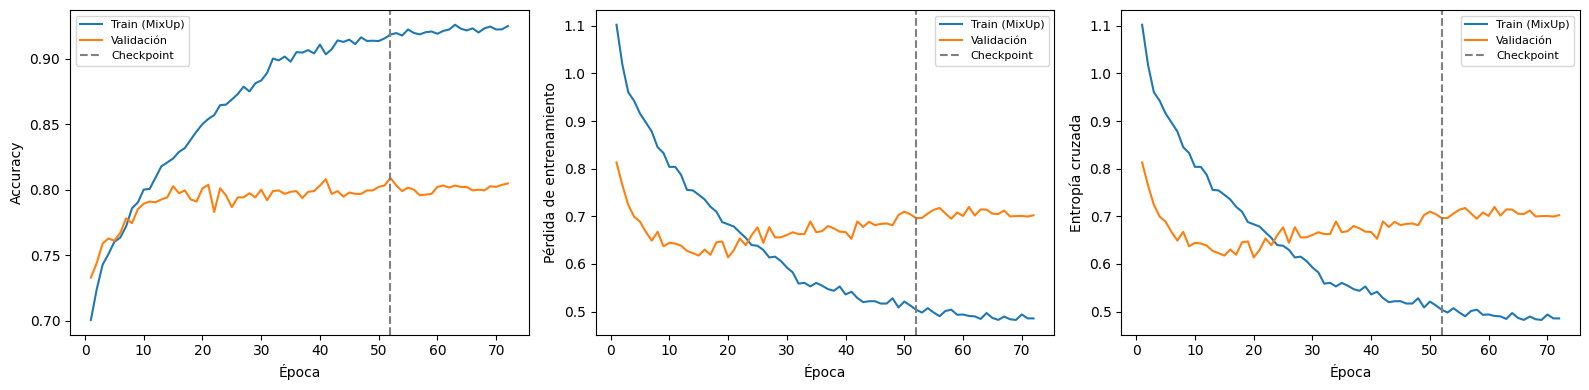

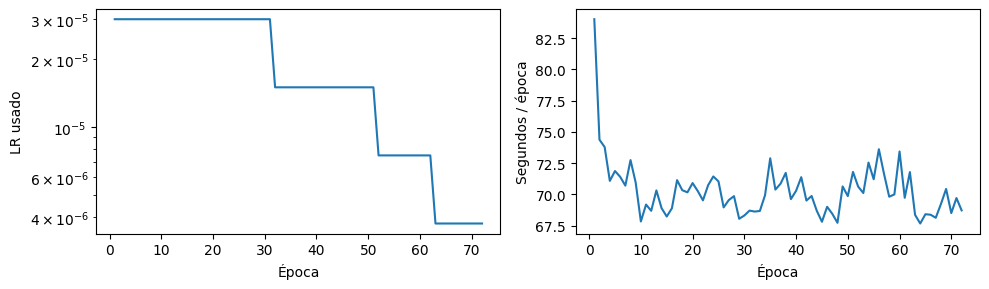

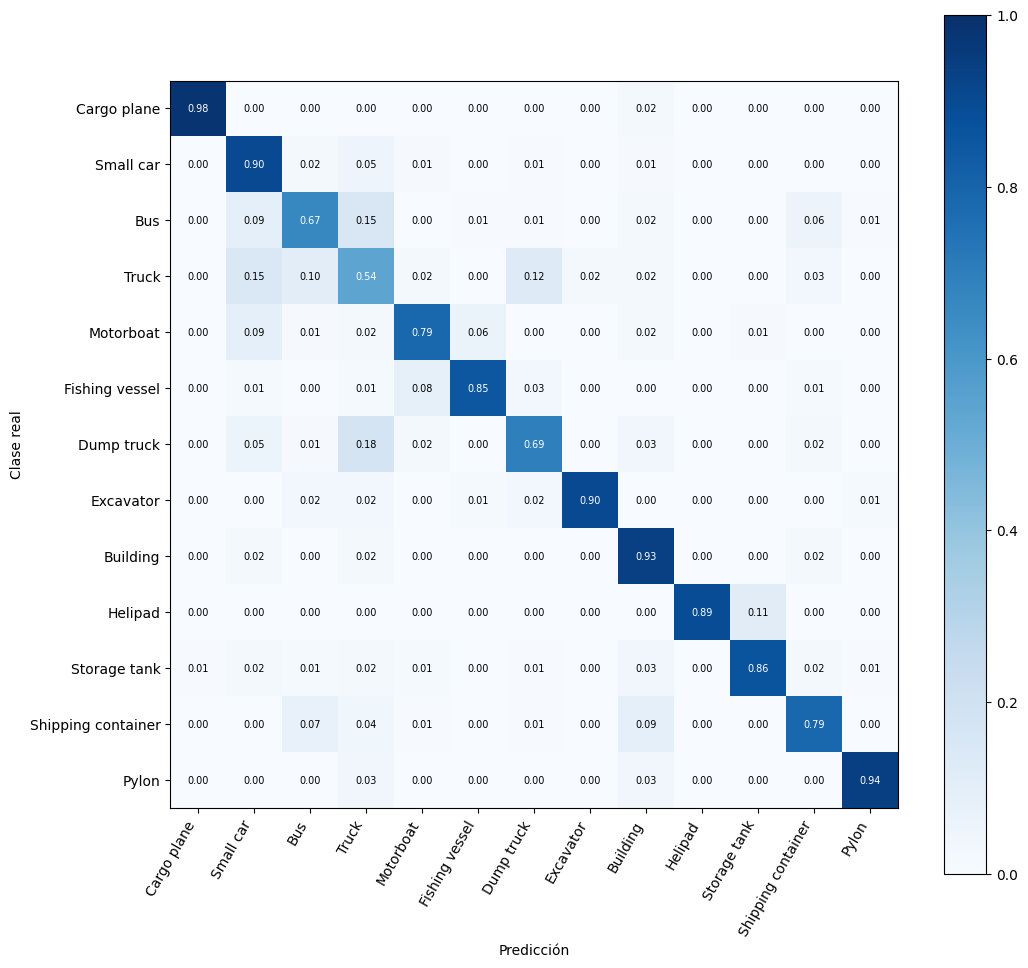

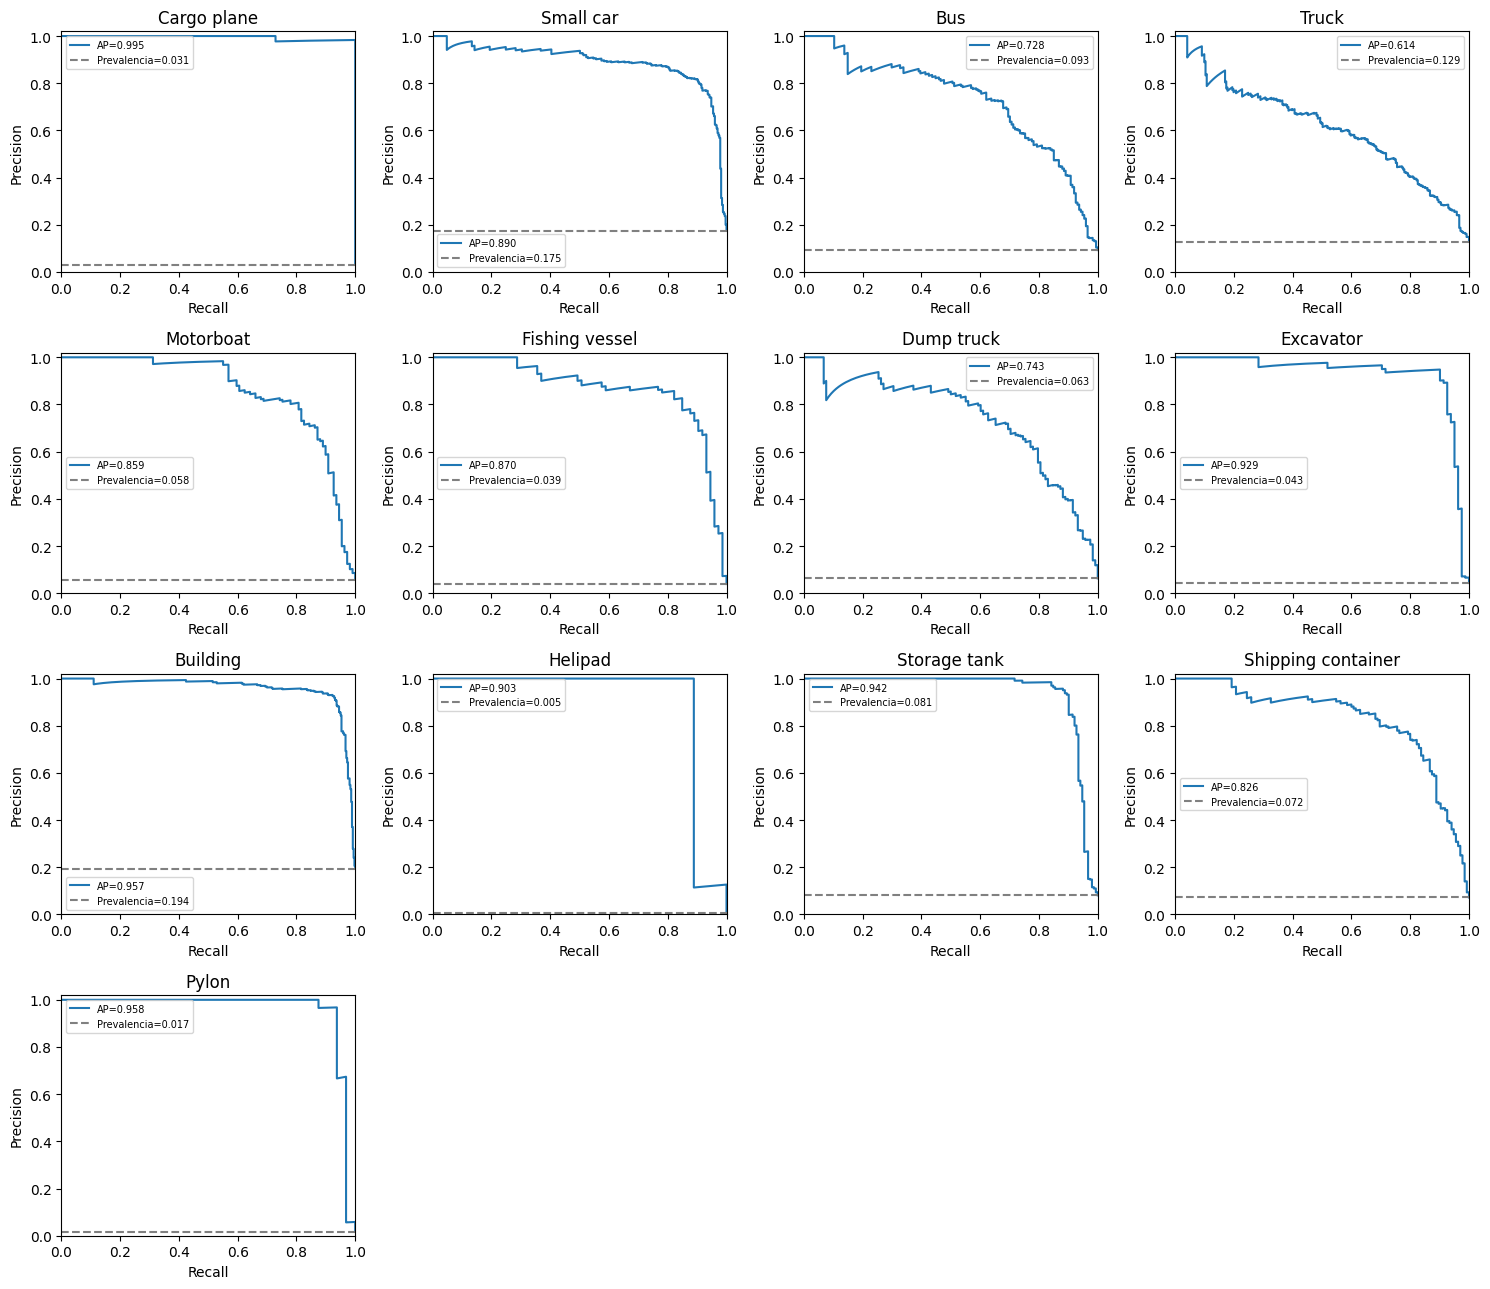

In [8]:
def plot_run(run_dir):
    cfg = read_json(artifact_path(run_dir, 'config.json'))
    h = read_json(artifact_path(run_dir, 'history.json'))
    m = read_json(artifact_path(run_dir, 'metrics.json'))
    classes = cfg['class_names']
    plots = run_dir / 'plots'
    epochs = np.arange(1, len(h['loss']) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, metric, title in zip(axes, ['accuracy', 'loss', 'ce'], ['Accuracy', 'Pérdida de entrenamiento', 'Entropía cruzada']):
        ax.plot(epochs, h[metric], label='Train (MixUp)' if cfg.get('mixup_alpha', 0) > 0 else 'Train (entrenamiento)')
        ax.plot(epochs, h['val_' + metric], label='Validación')
        if m.get('checkpoint_stage', cfg['stage']) == cfg['stage']:
            ax.axvline(m['best_epoch'], color='grey', ls='--', label='Checkpoint')
        else:
            ax.set_title('Checkpoint heredado del extractor')
        ax.set(xlabel='Época', ylabel=title)
        ax.legend(fontsize=8)
    save_figure(fig, plots, 'training_curves')
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].semilogy(epochs, h['lr_used'])
    axes[0].set(xlabel='Época', ylabel='LR usado')
    axes[1].plot(epochs, h['epoch_seconds'])
    axes[1].set(xlabel='Época', ylabel='Segundos / época')
    save_figure(fig, plots, 'learning_rate_time')
    with np.load(artifact_path(run_dir, 'validation_predictions.npz')) as saved:
        y, probs, cm = saved['y_true'], saved['probabilities'], saved['confusion_matrix']
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
    fig.colorbar(im, ax=ax)
    ax.set(xticks=range(len(classes)), yticks=range(len(classes)), xticklabels=classes,
           yticklabels=classes, xlabel='Predicción', ylabel='Clase real')
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f'{norm[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if norm[i, j] > 0.5 else 'black')
    save_figure(fig, plots, 'confusion_matrix')
    fig, axes = plt.subplots(4, 4, figsize=(15, 13))
    for i, (name, ax) in enumerate(zip(classes, axes.flat)):
        target = (y == i).astype(int)
        precision, recall, _ = precision_recall_curve(target, probs[:, i])
        ap = average_precision_score(target, probs[:, i])
        ax.plot(recall, precision, label=f'AP={ap:.3f}')
        ax.axhline(target.mean(), ls='--', color='grey', label=f'Prevalencia={target.mean():.3f}')
        ax.set(title=name, xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
        ax.legend(fontsize=7)
    for ax in list(axes.flat)[len(classes):]:
        ax.set_visible(False)
    save_figure(fig, plots, 'precision_recall')

plot_run(RUN_DIR)

## 9. Comparación con la misma arquitectura desde cero

SELECT_RUNS contiene rutas relativas a PROJECT. Se exige mismo dataset, reparto, clases y arquitectura;
se admiten tanto pesos aleatorios como ImageNet y distintas políticas de capas congeladas.
La etapa de extractor compara scratch y extractor; la de fine-tuning añade sus resultados a las dos anteriores.

Las curvas usan épocas locales de cada ejecución, no una trayectoria concatenada. Las tablas incluyen
etapa, procedencia del checkpoint, pesos, preprocesamiento, parámetros entrenables, tiempo local y acumulado.
El gráfico de coste usa tiempo acumulado: el fine-tuning incluye la preparación previa de la cabeza.
Si se hereda el extractor por no mejorar, las métricas seleccionadas coinciden con él, pero se conserva
el coste completo del intento de fine-tuning. Las diferencias de preprocesamiento y optimización son explícitas.

Después de reiniciar el kernel, basta la primera celda de código y esta sección; no se cargan imágenes
ni se construye el backbone. Se necesitan los artefactos completos de las ejecuciones seleccionadas.

Se comparan las siete ejecuciones. En experiment03, experiment04, experiment05 y experiment06, la curva de accuracy de train usa etiquetas
mezcladas y se omite de la figura comparativa; las curvas de validación siguen siendo comparables.
La tabla registra `mixup_alpha`, `unfreeze_scope` y los prefijos; la brecha usa siempre evaluación limpia.

La referencia scratch y experiment01/02/03/04 usan 128×128; experiment05 y experiment06 usan 192×192.
Se compara el efecto de la resolución, no únicamente de la inicialización. El tiempo acumulado
incluye la cabeza a 128 y esta rama a 192, sin sumar las otras ramas de fine-tuning.

La comparación principal experiment05–experiment06 mantiene resolución y pesos iniciales; solo cambia el LR inicial.


tl_challenge/efficientnet_b0/experiment06: acc=80.907%, F1=83.183%, CE=0.6962
tl_challenge/efficientnet_b0/experiment05: acc=80.160%, F1=82.015%, CE=0.6236
cnn_challenge_alt/popular_architectures/efficientnet_b0/experiment01: acc=77.973%, F1=78.400%, CE=0.7691
tl_challenge/efficientnet_b0/experiment04: acc=77.973%, F1=79.337%, CE=0.6711
tl_challenge/efficientnet_b0/experiment03: acc=76.960%, F1=79.254%, CE=0.7359
tl_challenge/efficientnet_b0/experiment02: acc=75.200%, F1=76.760%, CE=1.1581
tl_challenge/efficientnet_b0/experiment01: acc=70.720%, F1=71.664%, CE=0.8613


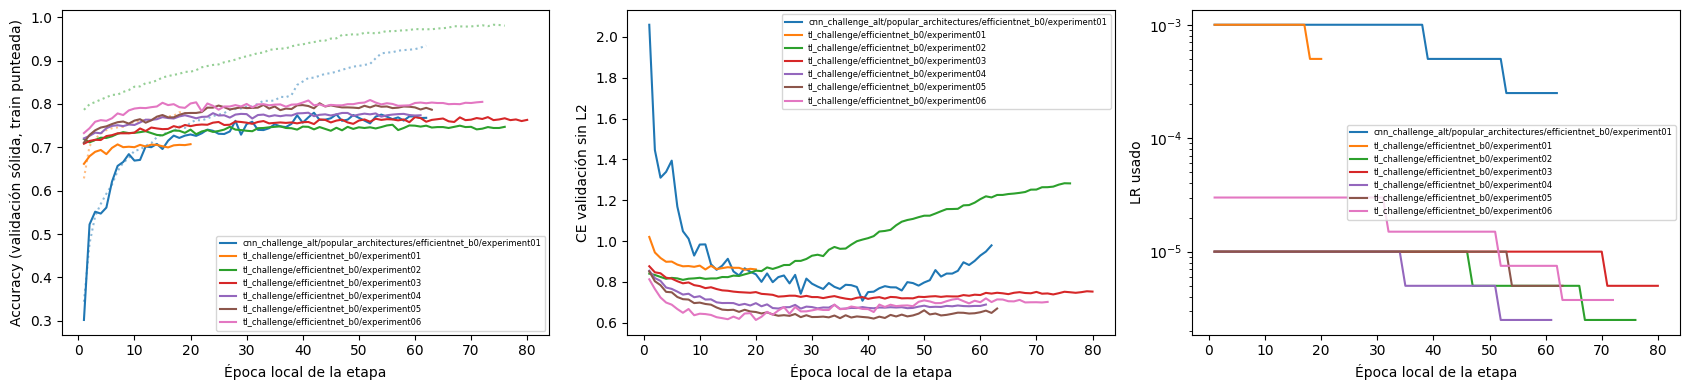

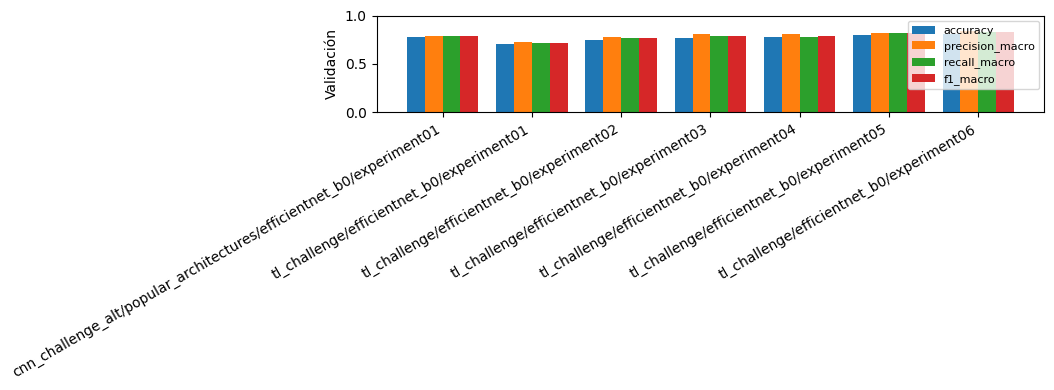

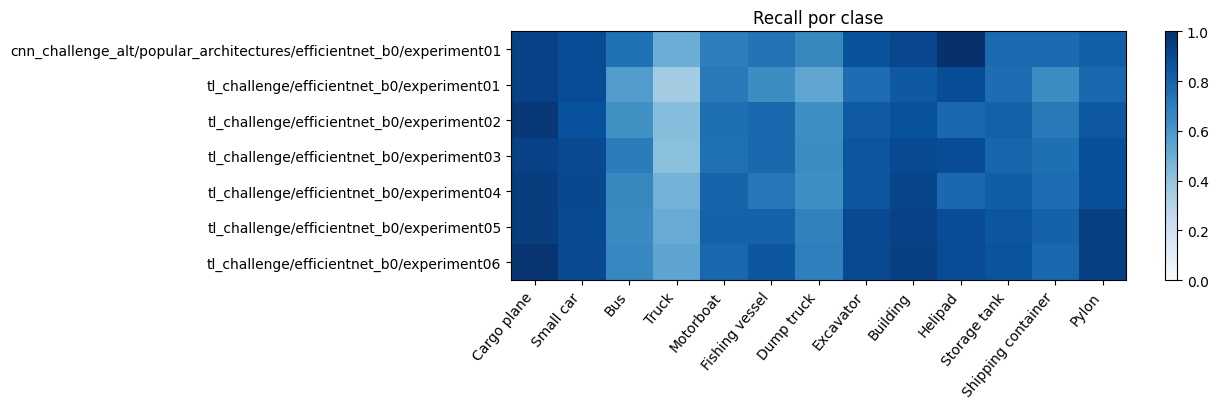

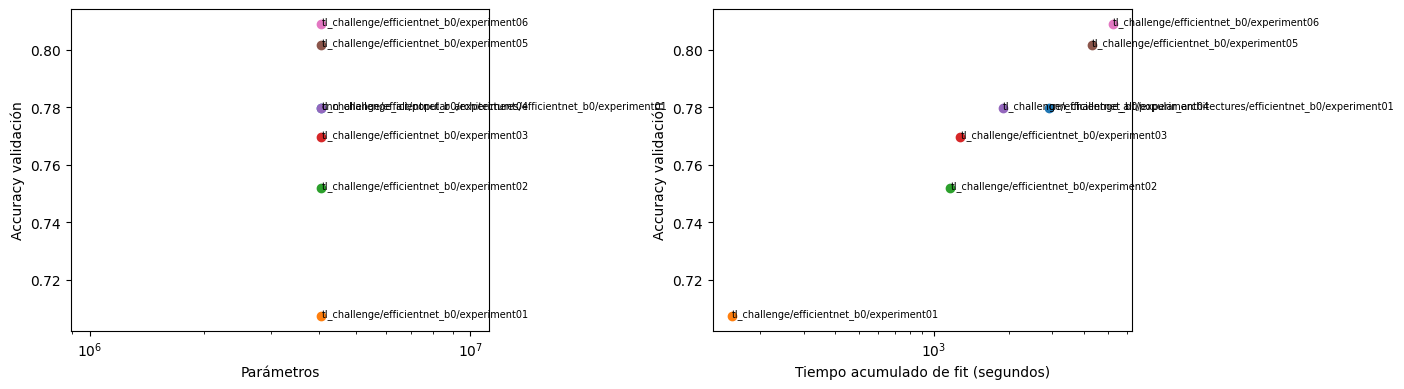

In [9]:
SELECT_RUNS = ['cnn_challenge_alt/popular_architectures/efficientnet_b0/experiment01',
 'tl_challenge/efficientnet_b0/experiment01',
 'tl_challenge/efficientnet_b0/experiment02',
 'tl_challenge/efficientnet_b0/experiment03',
 'tl_challenge/efficientnet_b0/experiment04',
 'tl_challenge/efficientnet_b0/experiment05',
 'tl_challenge/efficientnet_b0/experiment06']

def load_runs(challenge_dir, selected=None):
    if selected:
        paths = [challenge_dir / p for p in selected]
    else:
        paths = set()
        for metrics_path in challenge_dir.rglob('metrics.json'):
            path = metrics_path.parent.parent if metrics_path.parent.name == 'artifacts' else metrics_path.parent
            if all(artifact_path(path, name).is_file() for name in ('config.json', 'history.json')):
                paths.add(path)
        paths = sorted(paths)
    runs = []
    for path in paths:
        for name in ('config.json', 'metrics.json', 'history.json'):
            if not artifact_path(path, name).is_file():
                raise FileNotFoundError(f'Ejecución incompleta: {path} ({name})')
        cfg = read_json(artifact_path(path, 'config.json'))
        m = read_json(artifact_path(path, 'metrics.json'))
        h = read_json(artifact_path(path, 'history.json'))
        if m.get('schema_version') != 1:
            raise ValueError(f'Esquema de métricas incompatible: {path}')
        signature = (cfg['split_hash'], cfg['data_hash'], cfg['class_names'])
        if runs and signature != runs[0]['signature']:
            raise ValueError(f'Dataset/reparto/clases incompatibles: {path}')
        if runs and cfg['architecture'] != runs[0]['config']['architecture']:
            raise ValueError(f'Comparar la misma arquitectura: {path}')
        label = path.relative_to(challenge_dir).as_posix()
        runs.append({'path': path, 'config': cfg, 'metrics': m, 'history': h,
                     'label': label, 'signature': signature})
    return runs

def compare_runs(runs, directory):
    if not runs:
        print('Aún no hay experimentos completos para comparar.')
        return
    directory.mkdir(parents=True, exist_ok=True)
    rows = []
    for run in runs:
        c, m = run['config'], run['metrics']
        rows.append({'run': run['label'], 'architecture': c['architecture'], 'seed': c['seed'],
                     'resolution': 'x'.join(map(str, c['image_size'])), 'batch': c['batch_size'],
                     'optimizer': c['optimizer'], 'initial_lr': c['learning_rate'],
                     'stage': c.get('stage', 'scratch'), 'weights': c.get('weights'),
                     'checkpoint_stage': m.get('checkpoint_stage', 'scratch'),
                     'selected_from_source': m.get('selected_from_source', False),
                     'best_epoch_global': m.get('best_epoch_global', m['best_epoch']),
                     'epochs_total': m.get('epochs_total', m['epochs_run']),
                     'trainable_params_stage': c.get('trainable_params_stage', m['params']),
                     'unfreeze_scope': c.get('unfreeze_scope', 'prefixes' if c.get('stage') == 'fine_tuning' else c.get('stage', 'scratch')),
                     'unfreeze_prefixes': json.dumps(c.get('unfreeze_prefixes', [])),
                     'model_preprocessing': c.get('model_preprocessing', 'scratch_rgb_0_1'),
                     'dropout': c['dropout'], 'l2': c['l2'], 'augmentation': c['augmentation'],
                     'weight_decay': c.get('weight_decay', 0.0),
                     'label_smoothing': c.get('label_smoothing', 0.0),
                     'mixup_alpha': c.get('mixup_alpha', 0.0),
                     'augmentation_spec': json.dumps(c.get('augmentation_spec'), sort_keys=True),
                     'lr_factor': c['lr_factor'], 'lr_patience': c['lr_patience'],
                     'stop_patience': c['stop_patience'], 'min_lr': c['min_lr'],
                     'monitor': c['monitor'], 'max_epochs': c['max_epochs'],
                     'best_epoch': m['best_epoch'], 'epochs_run': m['epochs_run'],
                     'accuracy': m['accuracy'], 'precision_macro': m['precision_macro'],
                     'recall_macro': m['recall_macro'], 'f1_macro': m['f1_macro'], 'ap_macro': m['ap_macro'],
                     'ce': m['valid_inference']['ce'], 'gap_pp': m['accuracy_gap_pp'],
                     'params': m['params'], 'fit_seconds': m['fit_seconds'],
                     'fit_seconds_total': m.get('fit_seconds_total', m['fit_seconds']),
                     'predict_ms_per_image': m['predict_ms_per_image'],
                     'environment': json.dumps(c['environment'], sort_keys=True)})
    with (directory / 'comparison.csv').open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)
    for row in sorted(rows, key=lambda r: r['accuracy'], reverse=True):
        print(f"{row['run']}: acc={row['accuracy']:.3%}, F1={row['f1_macro']:.3%}, CE={row['ce']:.4f}")
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for run in runs:
        h = run['history']
        epochs = np.arange(1, len(h['loss']) + 1)
        line, = axes[0].plot(epochs, h['val_accuracy'], label=run['label'])
        if run['config'].get('mixup_alpha', 0) == 0:
            axes[0].plot(epochs, h['accuracy'], ls=':', color=line.get_color(), alpha=0.5)
        axes[1].plot(epochs, h['val_ce'], label=run['label'])
        axes[2].plot(epochs, h['lr_used'], label=run['label'])
    for ax, title in zip(axes, ['Accuracy (validación sólida, train punteada)', 'CE validación sin L2', 'LR usado']):
        ax.set(xlabel='Época local de la etapa', ylabel=title)
        ax.legend(fontsize=6)
    axes[2].set_yscale('log')
    save_figure(fig, directory, 'comparison_curves')
    names = [r['label'] for r in runs]
    x = np.arange(len(runs))
    fig, ax = plt.subplots(figsize=(max(9, len(runs) * 1.5), 4))
    for offset, key in enumerate(['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']):
        ax.bar(x + (offset - 1.5) * 0.2, [r['metrics'][key] for r in runs], width=0.2, label=key)
    ax.set(xticks=x, xticklabels=names, ylim=(0, 1), ylabel='Validación')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    ax.legend(fontsize=8)
    save_figure(fig, directory, 'comparison_metrics')
    matrix = np.array([[c['recall'] for c in r['metrics']['class_metrics']] for r in runs])
    fig, ax = plt.subplots(figsize=(13, max(3, len(runs) * 0.6)))
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set(xticks=range(len(runs[0]['config']['class_names'])), xticklabels=runs[0]['config']['class_names'],
           yticks=range(len(runs)), yticklabels=names, title='Recall por clase')
    plt.setp(ax.get_xticklabels(), rotation=50, ha='right')
    fig.colorbar(im, ax=ax)
    save_figure(fig, directory, 'comparison_class_recall')
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for run in runs:
        m = run['metrics']
        for ax, key in zip(axes, ['params', 'fit_seconds_total']):
            cost = m.get(key, m['fit_seconds'])
            ax.scatter(cost, m['accuracy'])
            ax.annotate(run['label'], (cost, m['accuracy']), fontsize=7)
    for ax, title in zip(axes, ['Parámetros', 'Tiempo acumulado de fit (segundos)']):
        ax.set(xlabel=title, ylabel='Accuracy validación', xscale='log')
    save_figure(fig, directory, 'comparison_cost')
    # Agrupar solo configuraciones idénticas salvo semilla e identidad de ejecución.
    ignored = {'seed', 'experiment_id', 'hypothesis', 'initial_weights_sha256', 'environment',
               'data_load_seconds', 'cache_mode', 'source_model_sha256', 'source_baseline_accuracy',
               'checkpoint_stage', 'selected_from_source', 'best_epoch_this_stage', 'best_epoch',
               'best_epoch_global', 'epochs_total'}
    groups = {}
    for run in runs:
        key = digest_json({k: v for k, v in run['config'].items() if k not in ignored})
        groups.setdefault(key, []).append(run)
    summary = []
    for group in groups.values():
        seeds = [r['config']['seed'] for r in group]
        if len(seeds) != len(set(seeds)):
            raise ValueError('Semillas duplicadas para una misma configuración: revisa SELECT_RUNS.')
        entry = {'runs': [r['label'] for r in group], 'seeds': seeds, 'n': len(group)}
        for metric in ['accuracy', 'recall_macro', 'f1_macro']:
            values = [r['metrics'][metric] for r in group]
            entry[metric + '_mean'] = float(np.mean(values))
            entry[metric + '_std'] = float(np.std(values, ddof=1)) if len(group) > 1 else None
        summary.append(entry)
    write_json(directory / 'seed_summary.json', summary)

runs = load_runs(PROJECT_DIR, SELECT_RUNS)
compare_runs(runs, CHALLENGE_DIR / 'comparisons' / 'efficientnet_b0_experiment06')


## 10. Resultados · completar tras entrenar

- **Arquitectura / etapa:** EfficientNetB0, fine_tuning.
- **Estado:** preparado; entrenamiento pendiente.
- **Mejor checkpoint:** ver `checkpoint_stage`, `best_epoch`, `best_epoch_global` y `selected_from_source`.
- **Accuracy, F1 macro, CE, AP y brecha en inferencia:** `artifacts/metrics.json`.
- **Mejora frente al entrenamiento desde cero de la misma arquitectura:** [completar].
- **Fine-tuning frente al extractor, si procede:** [completar; ¿se conservó el extractor?].
- **Épocas locales/totales, tiempo local/acumulado y parámetros entrenables:** [completar].
- **Clases que mejoran/empeoran y soporte de Helipad:** [completar].
- **LR 3e-5 frente a 1e-5 en experiment05 (80,16 %; F1 82,02 %; brecha 12,16 puntos; CE 0,6236):** [completar].
- **Conclusión:** [completar; una semilla y una partición, sin etiquetas de test].
- **Codabench si se envió:** [resultado independiente de validación].
